# LiDAR + RGB-D navigation scenario analysis

This notebook discovers runs under `outputs/lidar_rgbd_nav`, loads each `nav_lidar_trace.csv`, visualizes occupancy-grid evolution, and surfaces representative controller decision points.

Current artifact coverage:

- Occupancy-grid PNG sequences: available.
- Per-step trajectory, commands, LiDAR clearances, and RGB-D sector depths: available in CSV.
- Explicit continuous-controller replan decisions: not persisted; this notebook derives useful decision points from waypoint changes, steering extrema, safety events, and clearance minima.
- RGB screenshots and full depth images: displayed when present, but the existing runs did not save them. The final section explains what must be captured on future runs.


In [12]:
from __future__ import annotations

import csv
import html
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import numpy as np
from PIL import Image
from IPython.display import HTML, Markdown, display

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True})

def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "scripts" / "smoke_test_yolo_person_nav.py").is_file():
            return candidate
    raise FileNotFoundError("Could not locate the g1_rl project root. Start Jupyter inside this repository.")

PROJECT_ROOT = find_project_root()
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "lidar_rgbd_nav"
SUCCESS_RADIUS_M = 0.75
print(f"Project: {PROJECT_ROOT}")
print(f"Data:    {OUTPUT_ROOT}")


Project: /home/mosipov/g1_rl
Data:    /home/mosipov/g1_rl/outputs/lidar_rgbd_nav


## Discover and load runs

The loader intentionally avoids pandas so it works in the current `isaaclab` environment.


In [13]:
GRID_STEP_RE = re.compile(r"(\d+)(?=\.[^.]+$)")

def frame_step(path: Path) -> int:
    match = GRID_STEP_RE.search(path.name)
    return int(match.group(1)) if match else -1

def load_trace(path: Path) -> dict[str, np.ndarray]:
    with path.open(newline="", encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    if not rows:
        raise ValueError(f"Empty trace: {path}")

    result: dict[str, np.ndarray] = {}
    for name in rows[0]:
        values = [row[name] for row in rows]
        lowered = [value.lower() for value in values]
        if all(value in {"true", "false"} for value in lowered):
            result[name] = np.asarray([value == "true" for value in lowered], dtype=bool)
            continue
        try:
            result[name] = np.asarray([float(value) for value in values], dtype=float)
        except ValueError:
            result[name] = np.asarray(values, dtype=object)
    return result

def discover_runs(root: Path) -> dict[str, dict]:
    runs: dict[str, dict] = {}
    if not root.is_dir():
        return runs
    for directory in sorted(path for path in root.iterdir() if path.is_dir()):
        trace_path = directory / "nav_lidar_trace.csv"
        if not trace_path.is_file():
            continue
        grids = sorted((directory / "grid").glob("*.png"), key=frame_step)
        runs[directory.name] = {
            "directory": directory,
            "trace_path": trace_path,
            "trace": load_trace(trace_path),
            "grids": grids,
        }
    return runs

RUNS = discover_runs(OUTPUT_ROOT)
if not RUNS:
    raise FileNotFoundError(f"No scenario traces found below {OUTPUT_ROOT}")

print(f"Found {len(RUNS)} scenarios: {', '.join(RUNS)}")
for name, run in RUNS.items():
    print(f"  {name:14s} rows={len(run['trace']['step']):4d} grids={len(run['grids']):2d}")


Found 7 scenarios: clear, long_box, offset_left, offset_right, rotated_box, round, wide_box
  clear          rows= 587 grids=12
  long_box       rows=1092 grids=22
  offset_left    rows= 700 grids=14
  offset_right   rows= 701 grids=15
  rotated_box    rows=1030 grids=21
  round          rows= 901 grids=19
  wide_box       rows=1085 grids=22


## Cross-scenario summary


In [14]:
def finite_min(values: np.ndarray) -> float:
    finite = values[np.isfinite(values)]
    return float(np.min(finite)) if finite.size else math.nan

def summary_row(name: str, run: dict) -> dict:
    trace = run["trace"]
    return {
        "scenario": name,
        "steps": int(trace["step"][-1]) + 1,
        "target first": float(trace["target_distance"][0]),
        "target last": float(trace["target_distance"][-1]),
        "clearance min": finite_min(trace["scenario_edge_clearance"]),
        "margin min": finite_min(trace["scenario_margin_slack"]),
        "LiDAR overrides": int(np.count_nonzero(trace["safety_override"])),
        "RGB-D overrides": int(np.count_nonzero(trace["rgbd_safety_override"])),
        "grids": len(run["grids"]),
    }

SUMMARY = [summary_row(name, run) for name, run in RUNS.items()]
headers = list(SUMMARY[0])
table = ["<table><thead><tr>"]
table.extend(f"<th>{html.escape(header)}</th>" for header in headers)
table.append("</tr></thead><tbody>")
for row in SUMMARY:
    table.append("<tr>")
    for header in headers:
        value = row[header]
        rendered = f"{value:.3f}" if isinstance(value, float) else str(value)
        table.append(f"<td>{html.escape(rendered)}</td>")
    table.append("</tr>")
table.append("</tbody></table>")
display(HTML("".join(table)))


scenario,steps,target first,target last,clearance min,margin min,LiDAR overrides,RGB-D overrides,grids
clear,587,3.200,0.748,2.782,2.432,0,0,12
long_box,1092,4.200,0.750,0.470,0.120,0,0,22
offset_left,700,3.200,0.748,0.467,0.117,0,0,14
offset_right,701,3.200,0.748,0.470,0.120,0,0,15
rotated_box,1030,3.700,0.750,0.475,0.125,0,0,21
round,901,3.200,0.740,0.473,0.123,0,0,19
wide_box,1085,3.700,0.748,0.471,0.121,0,0,22


## Select a scenario

Change `SCENARIO` and rerun the cells below.


In [15]:
SCENARIO = "offset_right" if "offset_right" in RUNS else next(iter(RUNS))
run = RUNS[SCENARIO]
trace = run["trace"]
print(f"Selected {SCENARIO}: {len(trace['step'])} rows, {len(run['grids'])} grid frames")


Selected offset_right: 701 rows, 15 grid frames


## Trajectory, commands, and sensor state


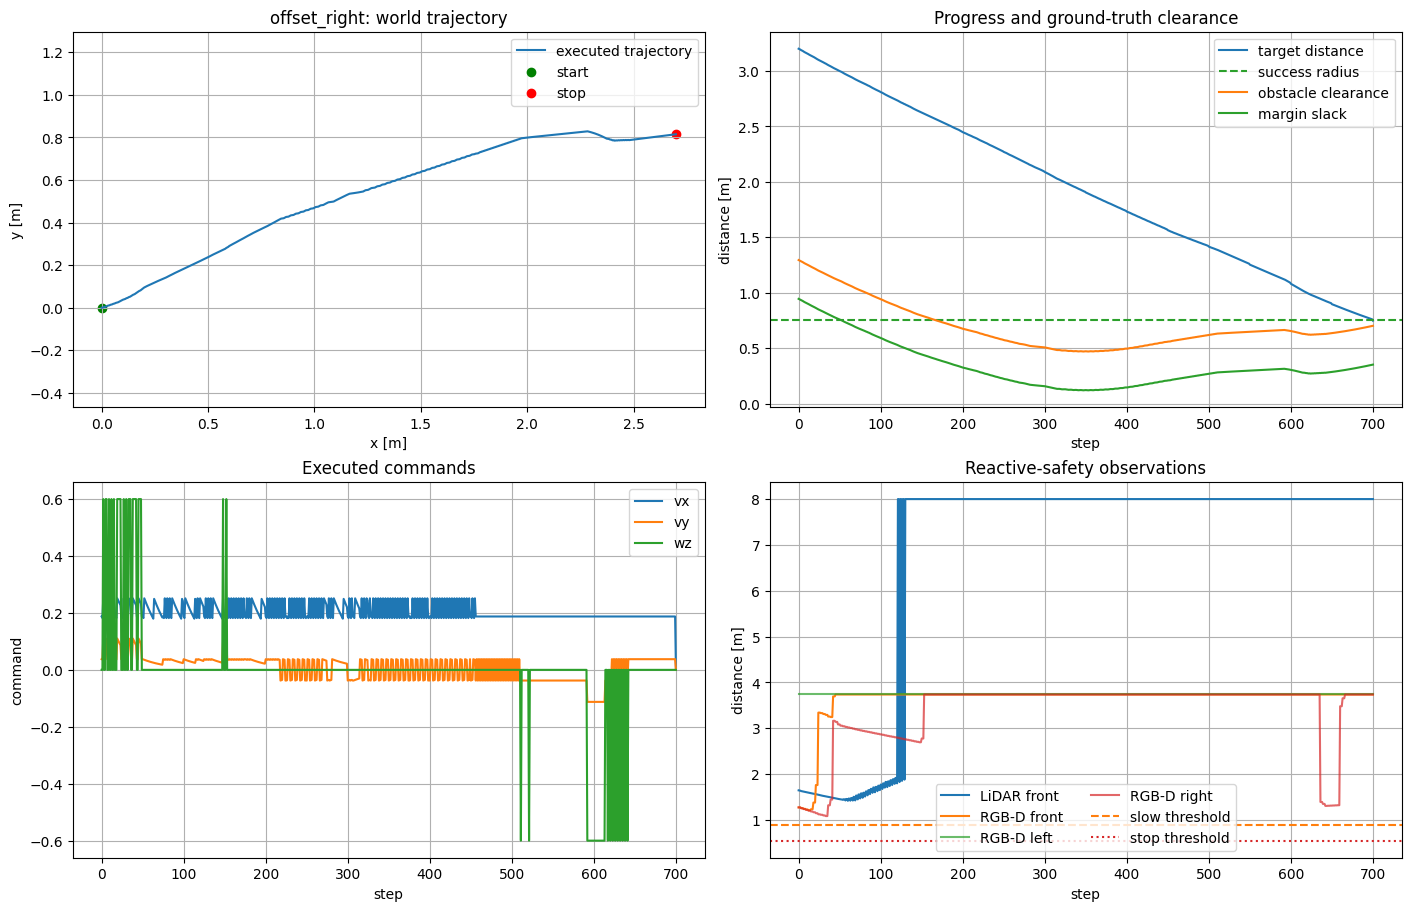

In [16]:
step = trace["step"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

axes[0, 0].plot(trace["x"], trace["y"], color="tab:blue", label="executed trajectory")
axes[0, 0].scatter(trace["x"][0], trace["y"][0], c="green", label="start")
axes[0, 0].scatter(trace["x"][-1], trace["y"][-1], c="red", label="stop")
axes[0, 0].set(title=f"{SCENARIO}: world trajectory", xlabel="x [m]", ylabel="y [m]")
axes[0, 0].axis("equal")
axes[0, 0].legend()

axes[0, 1].plot(step, trace["target_distance"], label="target distance")
axes[0, 1].axhline(SUCCESS_RADIUS_M, color="tab:green", linestyle="--", label="success radius")
axes[0, 1].plot(step, trace["scenario_edge_clearance"], label="obstacle clearance")
axes[0, 1].plot(step, trace["scenario_margin_slack"], label="margin slack")
axes[0, 1].set(title="Progress and ground-truth clearance", xlabel="step", ylabel="distance [m]")
axes[0, 1].legend()

for key in ("vx", "vy", "wz"):
    axes[1, 0].plot(step, trace[key], label=key)
axes[1, 0].set(title="Executed commands", xlabel="step", ylabel="command")
axes[1, 0].legend()

axes[1, 1].plot(step, trace["safety_front_clearance"], label="LiDAR front")
axes[1, 1].plot(step, trace["rgbd_safety_front_depth"], label="RGB-D front")
axes[1, 1].plot(step, trace["rgbd_safety_left_depth"], alpha=0.7, label="RGB-D left")
axes[1, 1].plot(step, trace["rgbd_safety_right_depth"], alpha=0.7, label="RGB-D right")
axes[1, 1].axhline(0.90, color="tab:orange", linestyle="--", label="slow threshold")
axes[1, 1].axhline(0.55, color="tab:red", linestyle=":", label="stop threshold")
axes[1, 1].set(title="Reactive-safety observations", xlabel="step", ylabel="distance [m]")
axes[1, 1].legend(ncol=2)
plt.show()


## Occupancy-grid dynamics

The storyboard shows evenly spaced saved frames. The animation uses every saved frame for the selected scenario.


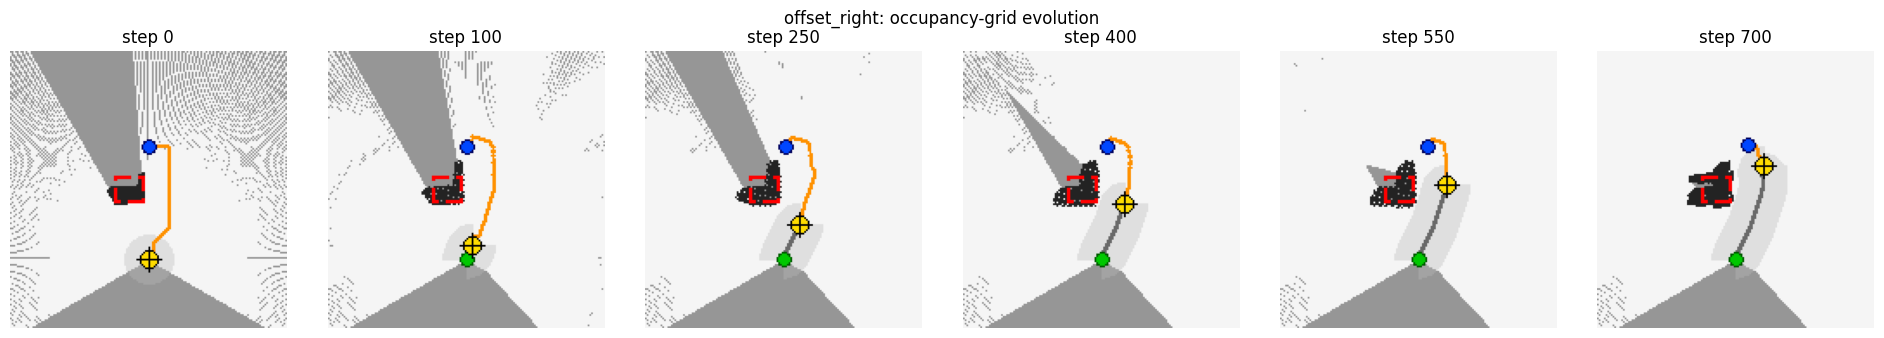

In [17]:
def show_grid_storyboard(scenario: str, count: int = 6) -> None:
    grids = RUNS[scenario]["grids"]
    if not grids:
        display(Markdown(f"**No grid images found for `{scenario}`.**"))
        return
    indices = np.unique(np.linspace(0, len(grids) - 1, min(count, len(grids)), dtype=int))
    fig, axes = plt.subplots(1, len(indices), figsize=(3.2 * len(indices), 3.4), squeeze=False)
    for axis, index in zip(axes[0], indices):
        path = grids[int(index)]
        axis.imshow(Image.open(path))
        axis.set_title(f"step {frame_step(path)}")
        axis.axis("off")
    fig.suptitle(f"{scenario}: occupancy-grid evolution")
    plt.tight_layout()
    plt.show()

show_grid_storyboard(SCENARIO)


In [18]:
def animate_occupancy(scenario: str, interval_ms: int = 350) -> HTML | Markdown:
    grids = RUNS[scenario]["grids"]
    if not grids:
        return Markdown(f"**No grid images found for `{scenario}`.**")
    images = [np.asarray(Image.open(path).convert("RGB")) for path in grids]
    fig, axis = plt.subplots(figsize=(6, 6))
    artist = axis.imshow(images[0])
    title = axis.set_title(f"{scenario} — step {frame_step(grids[0])}")
    axis.axis("off")

    def update(index: int):
        artist.set_data(images[index])
        title.set_text(f"{scenario} — step {frame_step(grids[index])}")
        return artist, title

    animation = FuncAnimation(fig, update, frames=len(images), interval=interval_ms, blit=False)
    plt.close(fig)
    return HTML(animation.to_jshtml())

display(animate_occupancy(SCENARIO))


## Derived decision points

Continuous-mode replan objects were not written to disk. The following points are reproducible proxies from the trace: start/goal, waypoint-index changes, peak steering, minimum ground-truth margin, minimum LiDAR clearance, minimum RGB-D depth, and any safety override. Each point is paired with the closest saved occupancy grid.


In [19]:
def derived_decision_points(trace: dict[str, np.ndarray]) -> list[dict]:
    reasons: dict[int, set[str]] = {}

    def add(index: int, reason: str) -> None:
        reasons.setdefault(int(index), set()).add(reason)

    add(0, "start")
    add(len(trace["step"]) - 1, "goal/stop")
    for index in np.flatnonzero(np.diff(trace["waypoint_index"]) != 0) + 1:
        add(int(index), "waypoint change")
    add(int(np.nanargmax(np.abs(trace["wz"]))), "peak |yaw command|")
    add(int(np.nanargmax(np.abs(trace["vy"]))), "peak |lateral command|")
    add(int(np.nanargmin(trace["scenario_margin_slack"])), "minimum margin slack")
    add(int(np.nanargmin(trace["safety_front_clearance"])), "minimum LiDAR front clearance")
    add(int(np.nanargmin(trace["rgbd_safety_front_depth"])), "minimum RGB-D front depth")
    for index in np.flatnonzero(trace["safety_override"]):
        add(int(index), "LiDAR safety override")
    for index in np.flatnonzero(trace["rgbd_safety_override"]):
        add(int(index), "RGB-D safety override")

    points = []
    for index in sorted(reasons):
        points.append({
            "index": index,
            "step": int(trace["step"][index]),
            "reason": ", ".join(sorted(reasons[index])),
            "waypoint": int(trace["waypoint_index"][index]),
            "target_m": float(trace["target_distance"][index]),
            "margin_m": float(trace["scenario_margin_slack"][index]),
            "lidar_front_m": float(trace["safety_front_clearance"][index]),
            "rgbd_front_m": float(trace["rgbd_safety_front_depth"][index]),
            "vy": float(trace["vy"][index]),
            "wz": float(trace["wz"][index]),
        })
    return points

DECISION_POINTS = derived_decision_points(trace)
columns = ("step", "reason", "waypoint", "target_m", "margin_m", "lidar_front_m", "rgbd_front_m", "vy", "wz")
rows = ["<table><thead><tr>" + "".join(f"<th>{name}</th>" for name in columns) + "</tr></thead><tbody>"]
for point in DECISION_POINTS:
    rows.append("<tr>")
    for column in columns:
        value = point[column]
        rendered = f"{value:.3f}" if isinstance(value, float) else str(value)
        rows.append(f"<td>{html.escape(rendered)}</td>")
    rows.append("</tr>")
rows.append("</tbody></table>")
display(HTML("".join(rows)))


step,reason,waypoint,target_m,margin_m,lidar_front_m,rgbd_front_m,vy,wz
0,start,3,3.200,0.944,1.647,1.275,0.038,0.000
2,"peak |yaw command|, waypoint change",4,3.193,0.937,1.640,1.275,0.110,0.600
3,waypoint change,3,3.188,0.932,1.631,1.259,0.038,0.000
5,waypoint change,4,3.180,0.925,1.624,1.259,0.110,0.600
7,waypoint change,3,3.170,0.916,1.615,1.244,0.038,0.000
9,waypoint change,4,3.163,0.909,1.609,1.229,0.110,0.600
10,waypoint change,3,3.158,0.904,1.604,1.229,0.038,0.000
12,"minimum RGB-D front depth, waypoint change",4,3.151,0.897,1.597,1.214,0.110,0.600
13,waypoint change,3,3.146,0.893,1.593,1.214,0.038,0.000
15,waypoint change,4,3.139,0.886,1.586,1.235,0.110,0.600


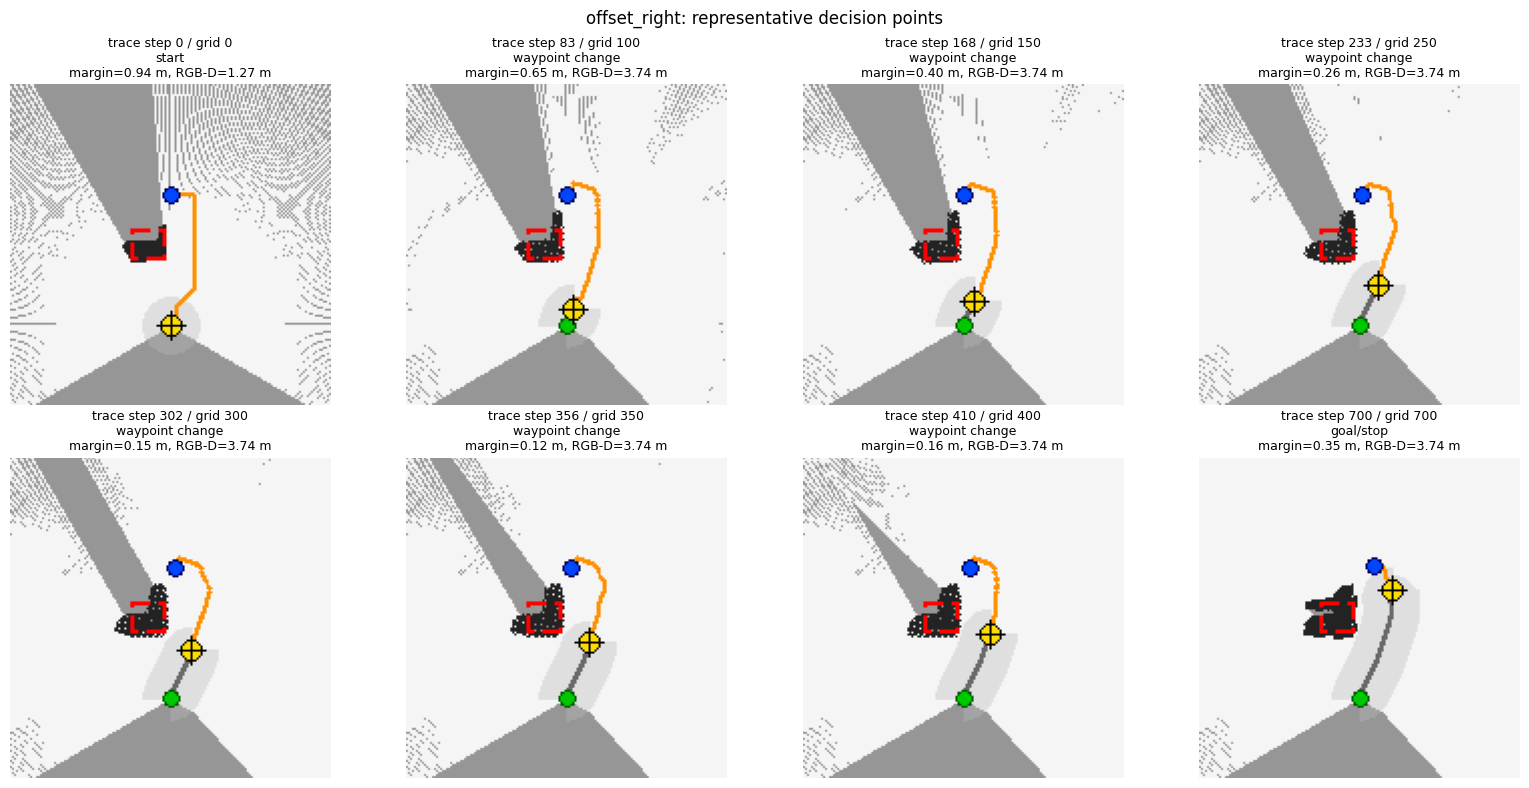

In [20]:
def closest_grid(grids: list[Path], step: int) -> Path | None:
    return min(grids, key=lambda path: abs(frame_step(path) - step)) if grids else None

def show_decision_examples(scenario: str, points: list[dict], max_examples: int = 8) -> None:
    grids = RUNS[scenario]["grids"]
    if not grids:
        display(Markdown("**No occupancy grids are available for decision-point examples.**"))
        return
    if len(points) > max_examples:
        selected_indices = np.unique(np.linspace(0, len(points) - 1, max_examples, dtype=int))
        points = [points[int(index)] for index in selected_indices]
    columns = min(4, len(points))
    rows = int(math.ceil(len(points) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4 * rows), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, point in zip(axes.flat, points):
        grid = closest_grid(grids, point["step"])
        axis.imshow(Image.open(grid))
        axis.set_title(
            f"trace step {point['step']} / grid {frame_step(grid)}\n"
            f"{point['reason']}\nmargin={point['margin_m']:.2f} m, RGB-D={point['rgbd_front_m']:.2f} m",
            fontsize=9,
        )
        axis.axis("off")
    fig.suptitle(f"{scenario}: representative decision points")
    plt.tight_layout()
    plt.show()

show_decision_examples(SCENARIO, DECISION_POINTS)


## RGB and depth artifacts

The existing traces contain RGB-D **sector summary depths**, not full depth frames. The gallery below searches both the scenario output and the script's default perception directory, then reports exactly what is available.


RGB artifacts:   60
Depth artifacts: 0


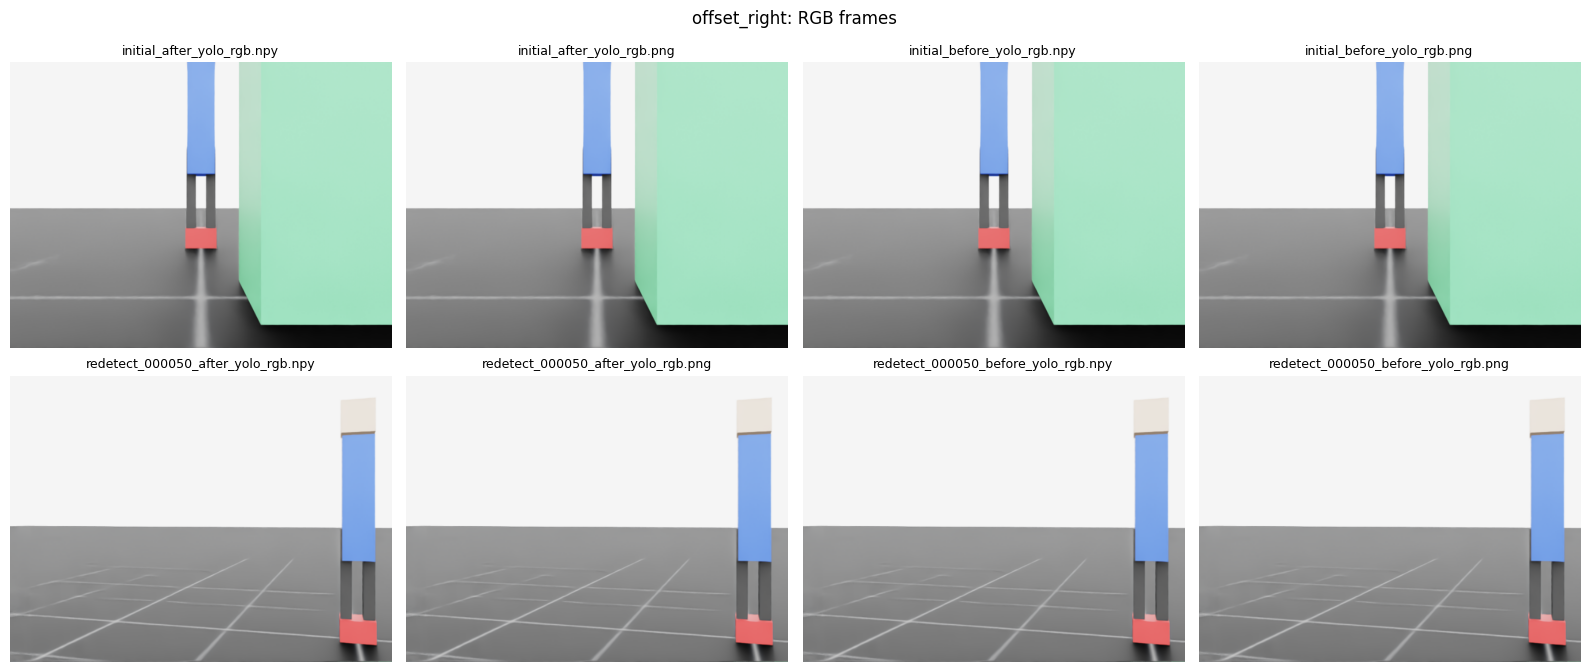

**offset_right: depth frames: no saved artifacts found.**

In [21]:
def discover_perception_artifacts(scenario: str) -> tuple[list[Path], list[Path]]:
    directories = [
        RUNS[scenario]["directory"] / "perception",
        PROJECT_ROOT / "outputs" / "yolo_person_nav" / scenario / "perception",
    ]
    files: list[Path] = []
    for directory in directories:
        if directory.is_dir():
            files.extend(path for path in directory.rglob("*") if path.is_file())
    files = sorted(set(files))
    rgb = [path for path in files if "rgb" in path.name.lower() and path.suffix.lower() in {".png", ".jpg", ".jpeg", ".npy"}]
    depth = [path for path in files if "depth" in path.name.lower() and path.suffix.lower() in {".png", ".jpg", ".jpeg", ".npy"}]
    return rgb, depth

def load_visual(path: Path) -> np.ndarray:
    if path.suffix.lower() == ".npy":
        return np.load(path)
    return np.asarray(Image.open(path))

def show_gallery(paths: list[Path], title: str, max_images: int = 8, *, depth: bool = False) -> None:
    if not paths:
        display(Markdown(f"**{title}: no saved artifacts found.**"))
        return
    paths = paths[:max_images]
    columns = min(4, len(paths))
    rows = int(math.ceil(len(paths) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.5 * rows), squeeze=False)
    for axis in axes.flat:
        axis.axis("off")
    for axis, path in zip(axes.flat, paths):
        image = load_visual(path)
        if depth:
            shown = axis.imshow(np.squeeze(image), cmap="viridis")
            fig.colorbar(shown, ax=axis, fraction=0.046)
        else:
            axis.imshow(image)
        axis.set_title(path.name, fontsize=9)
        axis.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

RGB_ARTIFACTS, DEPTH_ARTIFACTS = discover_perception_artifacts(SCENARIO)
print(f"RGB artifacts:   {len(RGB_ARTIFACTS)}")
print(f"Depth artifacts: {len(DEPTH_ARTIFACTS)}")
show_gallery(RGB_ARTIFACTS, f"{SCENARIO}: RGB frames")
show_gallery(DEPTH_ARTIFACTS, f"{SCENARIO}: depth frames", depth=True)


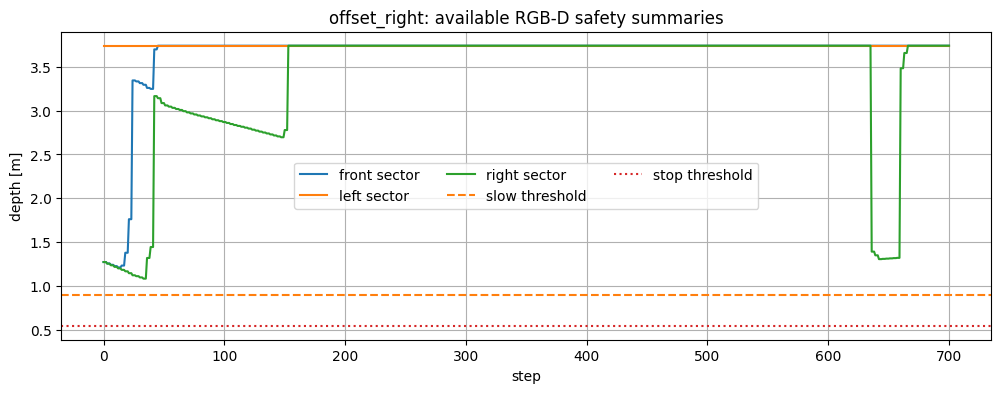

In [22]:
fig, axis = plt.subplots(figsize=(12, 4))
axis.plot(step, trace["rgbd_safety_front_depth"], label="front sector")
axis.plot(step, trace["rgbd_safety_left_depth"], label="left sector")
axis.plot(step, trace["rgbd_safety_right_depth"], label="right sector")
axis.axhline(0.90, color="tab:orange", linestyle="--", label="slow threshold")
axis.axhline(0.55, color="tab:red", linestyle=":", label="stop threshold")
axis.set(title=f"{SCENARIO}: available RGB-D safety summaries", xlabel="step", ylabel="depth [m]")
axis.legend(ncol=3)
plt.show()


## What to capture on the next run

RGB frames can be enabled with:

```text
--save_perception_images \
--perception_image_dir outputs/lidar_rgbd_nav/<scenario>/perception
```

That existing option saves initial/re-detection RGB frames and overlays; it does **not** save full depth images. Full synchronized depth frames and exact continuous-controller replan decisions require additional instrumentation in `scripts/smoke_test_yolo_person_nav.py`. Until then, this notebook uses the RGB-D sector-depth columns and derives decision points from the trace.
